### [GALT] Vežba 1: GAIA catalogue & basic statistics
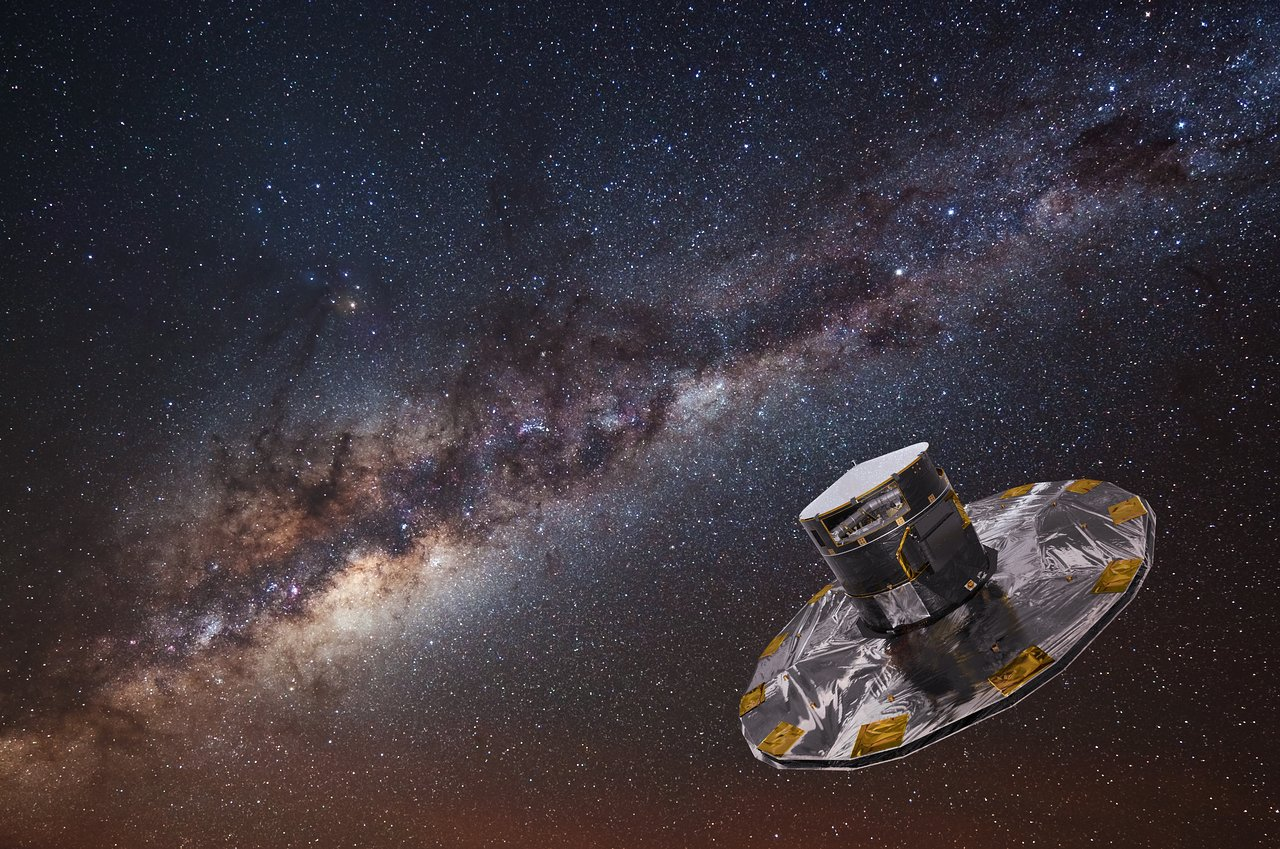

GAIA je svemirska astrometrijska misija Evropske svemirske agencije (ESA), čiji je osnovni cilj precizno merenje položaja i kretanja velikog broja astronomskih objekata. Lansirana je 19. decembra 2013. godine, a naučna posmatranja završena su 15. januara 2025. godine. Njeni podaci nastavljaju da se koriste za proučavanje strukture, kinematike i evolucije Mlečnog puta. Za razliku od teleskopa koji su prvenstveno usmereni na detaljno proučavanje pojedinačnih objekata, GAIA je osmišljena da sistematski posmatra veliki deo neba i stvori izuzetno obiman katalog astronomskih izvora.
Misija je omogućila da se proučavanje Galaksije pomeri sa zaključivanja na osnovu malog broja objekata na statističku analizu miliona i milijardi izvora.
Među najvažnijim rezultatima misije nalaze se:
- precizna merenja položaja zvezda na nebu;
- paralakse, na osnovu kojih možemo procenjivati udaljenosti;
- sopstvena kretanja zvezda po nebeskoj sferi;
- fotometrijska merenja u različitim opsezima talasnih dužina;
- radijalne brzine za deo posmatranih izvora;
- podaci o velikom broju dvojnih zvezda, promenljivih zvezda, jata i drugih astronomskih objekata.

Objavljivanje podataka odvijalo se u nekoliko izdanja. GAIA Data Release 3 (DR3) obuhvata približno 1,8 milijardi izvora, mada količina dostupnih podataka zavisi od vrste merenja i izabranog uzorka.

Podaci koje možemo da nađemo u katalogu su sledeći:

- _source_id_	- jedinstveni identifikator izvora u izdanju kataloga 
- _ra, dec_ - rektascenzija i deklinacija
- _l, b_ -	galaktička dužina i širina
- _parallax_ - paralaksa, u mililučnim sekundama (mas)
- _parallax_error_ - procena greške paralakse
- _pmra, pmdec_ - sopstvena kretanja u pravcu rektascenzije i deklinacije
- _phot_g_mean_mag_ - srednja prividna magnituda u GAIA \(G\) opsegu
- _bp_rp_ - indeks boje, razlika magnituda \(G_{\rm BP}-G_{\rm RP}\)
- _radial_velocity_ - radijalna brzina, dostupna samo za deo izvora

Ako želimo da preuzemo podatke, možemo da odemo na njihovu internet stranicu: https://www.cosmos.esa.int/web/gaia/data-release-3# gde možemo da koristimo _basic_ ili _advanced search_, u zavisnosti od toga šta nam je potrebno. Takođe, možemo direktno iz Python-a da komuniciramo sa bazom podataka, ali je za to neophodno da instaliramo __astroquery__ Python bibiloteku.

### <font color='yellow'>Ideja vežbe: Preuzimanje podataka iz različitih kataloga - za O zvezde iz GAIA DR3 kataloga, a za otvorena i globularna jata sa Vizier-a, i analiza datih podataka.</font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

Molim vas da ovu ćeliju koristite za sve biblioteke koje ćete naknadno da uvezete:

In [1]:
from astroquery.gaia import Gaia
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astroquery.vizier import Vizier
import astropy.units as u
from astropy.coordinates import Angle
from astropy.coordinates import SkyCoord

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


Sada hoćemo da nađemo podatke za zvezde tipa O i sačuvamo u dva odvojena fajla njihove rektascenzije, deklinacije i paralakse.

In [2]:
# zvezde spektralnog tipa O (Teff >= 30,000 K)
# uzimamo samo 2000

o_query = """
SELECT TOP 3000
    g.source_id, 
    g.ra, 
    g.dec, 
    g.parallax, 
    g.parallax_over_error, 
    g.pmra, 
    g.pmdec, 
    g.phot_g_mean_mag, 
    g.bp_rp,
    a.teff_gspphot
FROM gaiadr3.gaia_source AS g
JOIN gaiadr3.astrophysical_parameters AS a ON g.source_id = a.source_id
WHERE a.teff_gspphot >= 30000
  AND g.parallax > 0
  AND g.parallax_over_error > 5
"""

job_o = Gaia.launch_job_async(o_query)
df_o = job_o.get_results().to_pandas()
df_o.to_csv("o_stars.csv", index=False)

INFO: Query finished. [astroquery.utils.tap.core]


In [3]:
# učitavam podatke za O: ra, dec i parallax
df_o = pd.read_csv("o_stars.csv")
o_data = df_o[["ra", "dec", "parallax"]]

Sada preuzimamo podatke za otvorena jata: Optically visible open clusters and Candidates (Dias+ 2002-2015)

https://vizier.cds.unistra.fr/viz-bin/VizieR-3?-source=B/ocl/clusters

In [4]:
# učitavamo celi katalog - Vizier ima svoj row limit
Vizier.ROW_LIMIT = -1

# globularna jata
globular_result = Vizier.get_catalogs("VII/202")
df_globular = globular_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_globular_clean = df_globular[["ID", "RAJ2000", "DEJ2000"]]
df_globular_clean.to_csv("globular_clusters_harris.csv", index=False)

# otvorena jata
open_result = Vizier.get_catalogs("B/ocl")
df_open = open_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_open_clean = df_open[["RAJ2000", "DEJ2000", "Dist"]]
df_open_clean.to_csv("open_clusters_dias.csv", index=False)

##### <font color="green">1.  Prikazati grafik DEC od RA, pri čemu razlicitim simbolima oznaciti otvorena zvezdana jata i O zvezde.</font>

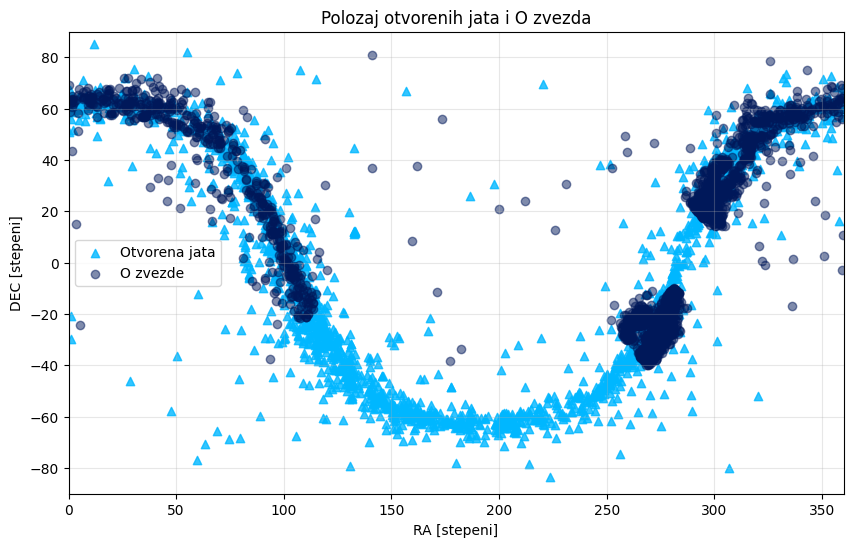

In [14]:
# ucitavanje podataka za otvorena zvezdana jata i o zvezda
open_ra_deg = Angle(df_open_clean["RAJ2000"], unit=u.hourangle).degree # konverzija rektascenzije iz sati u stepene
open_dec_deg = Angle(df_open_clean["DEJ2000"], unit=u.deg).degree # konverzija deklinacije iz deg min sec u samo stepene

o_ra_deg = pd.to_numeric(o_data["ra"]) # konverziju za o zvede nije potrebno raditi jer su vec date u stepenima
o_dec_deg = pd.to_numeric(o_data["dec"])

plt.figure(figsize=(10, 6))
plt.scatter(open_ra_deg, open_dec_deg, marker="^", label="Otvorena jata", color="#00b7ff", alpha=0.8)
plt.scatter(o_ra_deg, o_dec_deg, label="O zvezde", color="#00185A", alpha=0.5)
plt.xlabel("RA [stepeni]")
plt.ylabel("DEC [stepeni]")
plt.title("Polozaj otvorenih jata i O zvezda")
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.grid(True, alpha=0.3)
plt.legend(loc="best")
plt.show()

Otvorena jata i O zvezde su mladi objekti Mlecnog puta koji leze u disku galaksije, pa se na nebu nizu duz galakticke ravni. Kada se ta galakticka ravan projektuje na grafiku ekvatorskih nebeskih koordinata dobija se oblik sinusoide. Vidimo da se O zvezde grupisu, i najgusca grupacija je tamo gde je i disk najgusci i ima najvise zvezda. Jata su ravnomerno rasporedjena i prate celu krivu. Tacke van krive su razumljive jer jata nisu savrseno na disku, dok O zvezde van grupacija mogu biti pobegle/izbacene zvezde.

#### <font color="green">2. Odrediti udaljenosti do O zvezda. (Hint: Obratiti pažnju u kojoj jedinici je data paralaksa.)</font>

In [6]:
o_stars = pd.read_csv("o_stars.csv")
o_stars["distance_pc"] = 1000/o_stars["parallax"] # 1arcsec = 1000mas, d[pc] = 1/paralaksa[arcsec]
o_stars.to_csv("o_stars.csv", index=False)

print(f"Udaljenost je izracunata za {len(o_stars)} O zvezda i sacuvana u koloni distance_pc.")
print(o_stars.head()) # prikaz za prvih 5 O zvezda

Udaljenost je izracunata za 3000 O zvezda i sacuvana u koloni distance_pc.
            source_id         ra        dec  parallax  parallax_over_error  \
0  251377396389847296  56.038202  50.840431  0.684036            29.455648   
1  252878401557369088  70.247207  44.530344  0.378823            25.183200   
2  259863530209628032  74.083661  51.309293  0.164906             6.856781   
3  259961764700891136  74.440438  51.603512  0.408472            12.124949   
4  270308405340125568  63.879809  48.854653  0.430449            12.974833   

       pmra     pmdec  phot_g_mean_mag     bp_rp  teff_gspphot  distance_pc  
0 -0.597650 -2.547787        12.243650  3.080766     36443.312  1461.911048  
1  0.100646 -1.186128        10.403856  1.041190     32531.658  2639.752590  
2  2.195786 -2.152464        14.521197  3.058454     31849.932  6064.050551  
3  1.422370  0.288878        12.588949  3.490390     34983.004  2448.149775  
4  0.489562 -3.827072        12.554031  3.336836     30705.857  23

#### <font color="green">3. Određivanje položaja severnog galaktičkog pola</font>

Fitovati podatke funkcijom (zajedno podatke za O zvezde i otvorena jata) koja predstavlja veliki krug na nebeskoj sferi:

$$ \tan(\mathrm{\delta}) = \sin(\mathrm{\alpha}-\mathrm{\alpha}_{\omega})\tan(i), $$

gde su parametri fita $\mathrm{\alpha}_{\omega}$ i $i$.

Položaj severnog galaktičkog pola određuje se pomoću relacija:

$$ \mathrm{\alpha}_{\mathrm{PNG}} = \mathrm{\alpha}_{\omega} - 6\,\mathrm{h},$$

$$ \mathrm{\delta}_{\mathrm{PNG}} = 90^\circ - i.$$

Na osnovu dobijenih parametara fita odrediti koordinate severnog galaktičkog pola.

Dobijene vrednosti uporediti sa usvojenim vrednostima za epohu J2000:

$$ i = 62.87^\circ,
\qquad \mathrm{\alpha}_{\omega} = 18^\mathrm{h}51^\mathrm{m}26^\mathrm{s}.$$

Na grafiku prikazati posmatrane podatke i teorijsku funkciju velikog kruga nebeske sfere, definisanu jednačinom iznad.


Vrednosti dobijene fit-om:
alpha_omega = 284.523 deg; i = 61.567 deg
NGP_RA = 194.523 deg, NGP_DEC = 28.433 deg

Vrednosti za epohu J2000:
alpha_omega = 282.858 deg; i = 62.87 deg
NGP_RA = 192.859 deg, NGP_DEC 27.13 deg


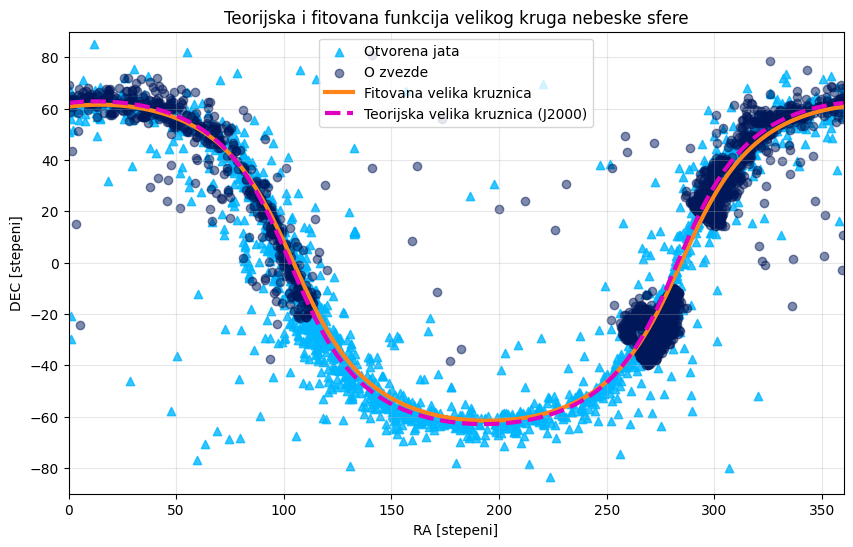

In [15]:
# ucitavanje i konverzija podataka za o zvezde i otvorena jata (identicno kao u zadatku 1)
o_fit = pd.read_csv("o_stars.csv")
open_fit = pd.read_csv("open_clusters_dias.csv")

o_ra_deg = o_fit["ra"].to_numpy()
o_dec_deg = o_fit["dec"].to_numpy()

open_ra_deg = Angle(open_fit["RAJ2000"], unit=u.hourangle).degree
open_dec_deg = Angle(open_fit["DEJ2000"], unit=u.deg).degree

ra_all = np.concatenate([o_ra_deg, open_ra_deg]) # stavljanje rektascenzija za O zvezde i otvorena jata u jedan niz
dec_all = np.concatenate([o_dec_deg, open_dec_deg]) # stavlja se u 1 niz zbog fita jer se fit radi nad svim podacima

# fitovanje podataka
def veliki_krug(ra, alpha_omega, inc):
    return np.degrees(np.arctan(
        np.sin(np.radians(ra - alpha_omega)) * np.tan(np.radians(inc))
    ))

fit, _ = curve_fit(
    veliki_krug, ra_all, dec_all,
    bounds=([0, 0], [360, 90])
)

alpha_omega, inklinacija = fit
ngp_ra = (alpha_omega - 90) % 360
ngp_dec = 90 - inklinacija

print("Vrednosti dobijene fit-om:")
print(f"alpha_omega = {alpha_omega:.3f} deg; i = {inklinacija:.3f} deg")
print(f"NGP_RA = {ngp_ra:.3f} deg, NGP_DEC = {ngp_dec:.3f} deg\n")

print("Vrednosti za epohu J2000:")
print("alpha_omega = 282.858 deg; i = 62.87 deg")
print("NGP_RA = 192.859 deg, NGP_DEC 27.13 deg")

ra_curve = np.linspace(0, 360, 1000)
alpha_omega_theory = Angle("18h51m26s").degree
inclination_theory = 62.87

plt.figure(figsize=(10, 6))
plt.scatter(open_ra_deg, open_dec_deg, marker="^", label="Otvorena jata", color="#00b7ff", alpha=0.8)
plt.scatter(o_ra_deg, o_dec_deg, label="O zvezde", color="#00185A", alpha=0.5)
plt.plot(ra_curve, veliki_krug(ra_curve, *fit), color="#ff8519", label="Fitovana velika kruznica", linewidth=3)
plt.plot(ra_curve, veliki_krug(ra_curve, alpha_omega_theory, inclination_theory), color="#DF00C1", linestyle="--", label="Teorijska velika kruznica (J2000)", linewidth=3)
plt.xlabel("RA [stepeni]")
plt.ylabel("DEC [stepeni]")
plt.title("Teorijska i fitovana funkcija velikog kruga nebeske sfere")
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.grid(True, alpha=0.3)
plt.legend(loc="best")
plt.show()

Fit se ne poklapa tacno sa teorijskom krivom jer grupe O zvezda, koja su sa desne strane grafika, su gusce i "vuku" fit na tu stranu.

#### <font color="green">4. Izračunati galaktičke koordinate l i b za globularna jata. (Možete npr. koristiti funkciju SkyCoord.)</font>

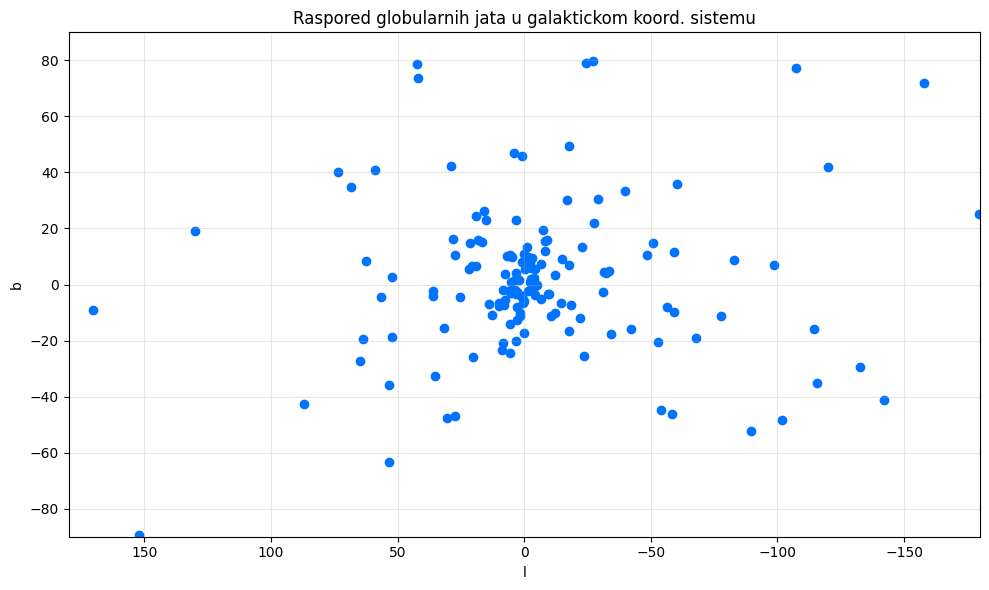

In [8]:
df = pd.read_csv("globular_clusters_harris.csv")

# opet paziti kako je zadata rektascenzija a kako deklinacija
coord_j2000 = SkyCoord(
    ra=df["RAJ2000"].astype(str),
    dec=df["DEJ2000"].astype(str),
    unit=(u.hourangle, u.deg),
    frame="fk5",
)
coord_galactic = coord_j2000.galactic

df["l"] = coord_galactic.l.deg
df["b"] = coord_galactic.b.deg
df.to_csv("globular_clusters_harris.csv", index=False)

# transformacija za l d bi galakticki centar bio na sredini gafika
df["l_plot"] = np.where(df["l"] > 180, df["l"] - 360, df["l"])

plt.figure(figsize=(10, 6))
plt.scatter(df["l_plot"], df["b"], marker="o", color="#0073ff")
plt.xlabel("l")
plt.ylabel("b")
plt.title("Raspored globularnih jata u galaktickom koord. sistemu")
plt.xlim(180, -180)
plt.ylim(-90, 90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

l je prikazano od -180 do 180 stepeni samo radi lepseg prikaza na grafiku(u csv-u se moze videti da ide od 0 do 360 kako je zapravo i definisano galaktickim koord. sistemom) gde tacno mozemo da vidimo kako se globularna jata nalaze svuda u galaksiji. Najmasivnija globularna jata nalaze se u galaktickom jezgru gde preovladjuju starije zvezde kako idemo od centra ka drugim delovima galaksije njihov broj opada.

#### <font color="green">5. Galaktička latituda centra prividne raspodele.</font>
Odrediti galaktičku latitudu centra prividne raspodele globularnih jata. Kreirati prvo zone (pojase) jednakih površina na nebeskoj sferi, njih 10. Površina omotača jednog pojasa je  $2\pi h$, kako je $R=1$ za nebesku sferu. Kako nas zanima da izdelimo nebesku sferu na 10 zona, da je površina jednog omotača zapravo deseti deo površine cele nebeske sfere =>  $2\pi h=0.4\pi$, pa je visina $h = 0.2$, odnosno kako koristimo galaktički koordinatni sistem, prva zona od galaktičkog ekvatora $(b = 0)$ ide do $b = arcsin(0.2)$, kako je $R = 1$, a $sin(b) = h$ (vertikalna visina u odnosu na galaktički ekvator). Za granice zona imamo $b_j = arcsin(0.2(j-6))$, $j = 1, 2, 3, ..., 10$. Na sličan način se mogu naći galaktičke latitude koje odgovaraju centru pojasa, $b_{jc} = arcsin(0.2(j-6) + 0.1)$, $j = 1, 2, 3, ..., 10$. Zapravo, pravi se histogram po b, odnosno broje se objekti u konkretnim zonama. Grafički predstaviti histogram po galaktičkoj latitudi. Galaktička latituda maksimuma raspodele se može naći kao srednja vrednost tako grupisanih posmatranja:
$$b_{max} = \frac{\sum n_ib_i}{\sum n_i},$$
gde je $n_i$ broj zvezda u zoni čija je centralna galaktička latituda $b_i$. Proceniti  $b_{max}$ i za podelu od 20 zona. Koliko očekujemo da je  $b_{max}$, a kolika je računata vrednost?

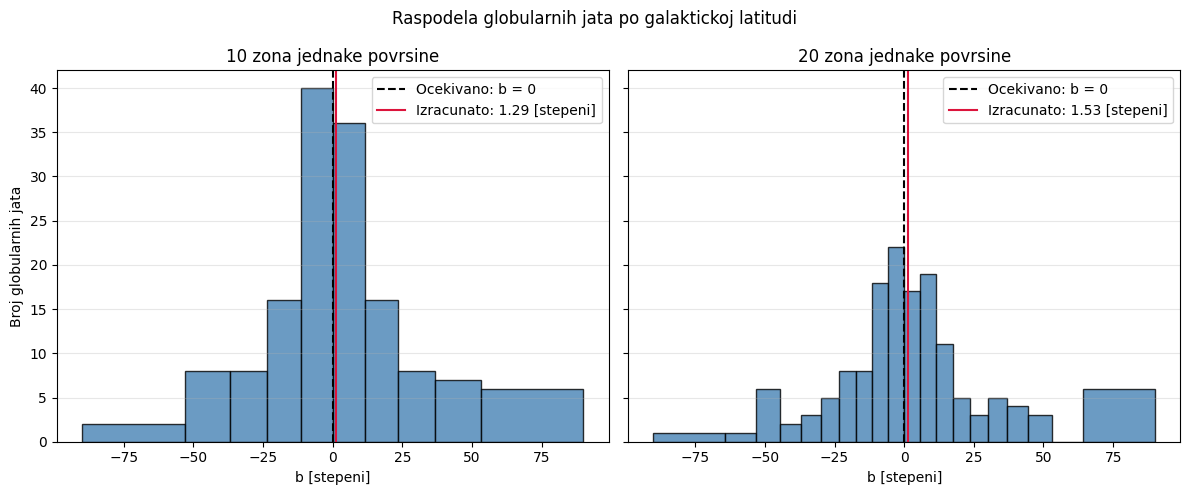

Broj jata: 147
Ocekivani centar raspodele: b_max = 0 [stepeni] (galakticka ravan)
10 zona: b_max = 1.29 [stepeni]
20 zona: b_max = 1.53 [stepeni]


In [ ]:
globular_data = pd.read_csv("globular_clusters_harris.csv")
b = pd.to_numeric(globular_data["b"], errors="coerce").dropna().to_numpy() # cistimo podatke u slucaju NaN vrednosti


def latitude_distribution(number_of_zones):
    sin_edges = np.linspace(-1, 1, number_of_zones + 1) # kako sinb = h prvo ide [-1,1]
    edges = np.degrees(np.arcsin(sin_edges)) # vracamo u stepene
    centers = np.degrees(np.arcsin((sin_edges[:-1] + sin_edges[1:]) / 2))
    counts, _ = np.histogram(b, bins=edges) # br jata u napravljenim zonama
    b_max = np.average(centers, weights=counts)
    return edges, centers, counts, b_max


fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
results = {}

for ax, number_of_zones in zip(axes, (10, 20)):
    edges, centers, counts, b_max = latitude_distribution(number_of_zones)
    results[number_of_zones] = b_max
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge",
       color="steelblue", edgecolor="black", alpha=0.8)
    ax.axvline(0, color="black", linestyle="--", label="Ocekivano: b = 0")
    ax.axvline(b_max, color="crimson", linestyle="-", label=f"Izracunato: {b_max:.2f} [stepeni]")
    ax.set_xlabel("b [stepeni]")
    ax.set_title(f"{number_of_zones} zona jednake povrsine")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Broj globularnih jata")
fig.suptitle("Raspodela globularnih jata po galaktickoj latitudi")
fig.tight_layout()
plt.show()

print(f"Broj jata: {len(b)}")
print("Ocekivani centar raspodele: b_max = 0 [stepeni] (galakticka ravan)")
for number_of_zones, b_max in results.items():
    print(f"{number_of_zones} zona: b_max = {b_max:.2f} [stepeni]")

Dobijene vrednosti centra raspodele su $b_{max}=1.29^\circ$ za 10 zona i $b_{max}=1.53^\circ$ za 20 zona. Ocekivana vrednost je približno $0^\circ$, jer bi centar raspodele globularnih jata trebalo da prati galakticku ravan. Rezultati su bliski ocekivanju, a malo pozitivno odstupanje moze biti posledica konacnog broja jata i njihove neravnomerne raspodele. Razlicit broj zona menja grupisanje objekata i centre pojaseva, pa se zato procena blago menja. Zone su jednake povrsine zato sto su granice ravnomerno rasporedjene po $\sin(b)$, a ne po samoj latitudi $b$.

#### <font color="green">6. Galaktička longituda centra prividne raspodele, slično kao prethodno.</font>

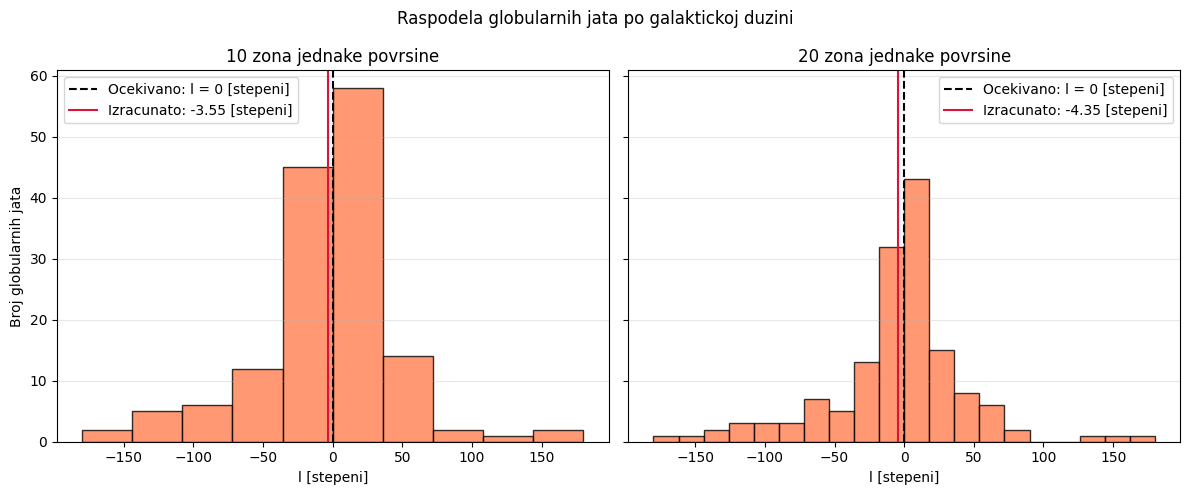

Broj jata: 147
Ocekivani centar raspodele: l_center = 0 [stepeni] (galakticki centar)
10 zona: l_center = -3.55 [stepeni]
20 zona: l_center = -4.35 [stepeni]


In [ ]:
globular_data = pd.read_csv("globular_clusters_harris.csv")
l = pd.to_numeric(globular_data["l"], errors="coerce").dropna().to_numpy()
l_wrapped = np.where(l > 180, l - 360, l)


# idej funkcije ista kao kada se radilo i za latitudu u zadatku iznad
def longitude_distribution(number_of_zones):
    edges = np.linspace(-180, 180, number_of_zones + 1)
    centers = (edges[:-1] + edges[1:]) / 2
    counts, _ = np.histogram(l_wrapped, bins=edges)
    l_center = np.average(centers, weights=counts)
    return edges, centers, counts, l_center


fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
results = {}

for ax, number_of_zones in zip(axes, (10, 20)):
    edges, centers, counts, l_center = longitude_distribution(number_of_zones)
    results[number_of_zones] = l_center
    ax.bar(centers, counts, width=np.diff(edges), color="coral", edgecolor="black", alpha=0.8)
    ax.axvline(0, color="black", linestyle="--", label="Ocekivano: l = 0 [stepeni]")
    ax.axvline(l_center, color="crimson", linestyle="-", label=f"Izracunato: {l_center:.2f} [stepeni]")
    ax.set_xlabel("l [stepeni]")
    ax.set_title(f"{number_of_zones} zona jednake povrsine")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Broj globularnih jata")
fig.suptitle("Raspodela globularnih jata po galaktickoj duzini")
fig.tight_layout()
plt.show()

print(f"Broj jata: {len(l_wrapped)}")
print("Ocekivani centar raspodele: l_center = 0 [stepeni] (galakticki centar)")
for number_of_zones, l_center in results.items():
    print(f"{number_of_zones} zona: l_center = {l_center:.2f} [stepeni]")

Dobijene vrednosti centra raspodele po galaktičkoj duzini su približno $l_{max}=-3.55^\circ$ za 10 zona i $l_{max}=-4.35^\circ$ za 20 zona. Ocekivana vrednost je priblizno $0^\circ$, jer bi centar raspodele globularnih jata trebalo da bude usmeren ka galaktickom centru. Malo odstupanje je posledica konacnog broja objekata, njihove neravnomerne raspodele i nacina grupisanja po zonama. Kako je galakticki centar na $l=0^\circ$, rezultati pokazuju da je raspodela koncentrisana u pravcu centra Galaksije.

#### <font color="green">7. Ako pretpostavimo da je centar prividne raspodele globularnih jata upravo centar naše galaksije, kolike su onda l i b galaktičkog centra (koliko očekujemo i koje vrednosti su izračunate)? Kolike su onda RA i DEC za J2000, središta naše galaksije (uporediti sa koordinatama Sag A*).</font>

In [ ]:
globular_data = pd.read_csv("globular_clusters_harris.csv")

l_data = pd.to_numeric(globular_data["l"], errors="coerce").dropna().to_numpy()
b_data = pd.to_numeric(globular_data["b"], errors="coerce").dropna().to_numpy()

# funkcije iz 5 i 6 zadatka spakovane u jednu 
def center_from_equal_area(values, number_of_zones, mode):
    if mode == "longitude":
        edges = np.linspace(-180, 180, number_of_zones + 1)
        centers = (edges[:-1] + edges[1:]) / 2
        wrapped = np.where(values > 180, values - 360, values)
        counts, _ = np.histogram(wrapped, bins=edges)
    else:
        sin_edges = np.linspace(-1, 1, number_of_zones + 1)
        edges = np.degrees(np.arcsin(sin_edges))
        centers = np.degrees(np.arcsin((sin_edges[:-1] + sin_edges[1:]) / 2))
        counts, _ = np.histogram(values, bins=edges)
    return np.average(centers, weights=counts)

# racunanje l i b za 10 i 20 binova 
l_center_10 = center_from_equal_area(l_data, 10, "longitude")
b_center_10 = center_from_equal_area(b_data, 10, "latitude")
l_center_20 = center_from_equal_area(l_data, 20, "longitude")
b_center_20 = center_from_equal_area(b_data, 20, "latitude")

# galakticki centar iz centara raspodele za 10 i 20 zona
center_10 = SkyCoord(l=l_center_10 * u.deg, b=b_center_10 * u.deg, frame="galactic")
center_20 = SkyCoord(l=l_center_20 * u.deg, b=b_center_20 * u.deg, frame="galactic")
center_fk5_10 = center_10.transform_to("fk5") # iz gal u neb ekv koord sistem
center_fk5_20 = center_20.transform_to("fk5")

# ocekivani  centar: l = b = 0°
expected_center = SkyCoord(l=0 * u.deg, b=0 * u.deg, frame="galactic").transform_to("fk5")

# Sag A* (J2000) podaci
sag_a = SkyCoord("17h45m40.04s -29d00m28s", frame="icrs")

# print svih podataka za poredjenje
print(f"Centar raspodele (10 zona): l = {l_center_10:.2f}\xb0 , b = {b_center_10:.2f}\xb0 ")
print(f"RA = {center_fk5_10.ra.hms[0]:02.0f}h {center_fk5_10.ra.hms[1]:02.0f}m {center_fk5_10.ra.hms[2]:05.2f}s")
print(f"DEC = {center_fk5_10.dec.dms[0]:+03.0f}\xb0 {abs(center_fk5_10.dec.dms[1]):02.0f}' {abs(center_fk5_10.dec.dms[2]):05.2f}\"\n")

print(f"Centar raspodele (20 zona): l = {l_center_20:.2f}\xb0 , b = {b_center_20:.2f}\xb0")
print(f"RA = {center_fk5_20.ra.hms[0]:02.0f}h {center_fk5_20.ra.hms[1]:02.0f}m {center_fk5_20.ra.hms[2]:05.2f}s")
print(f"DEC = {center_fk5_20.dec.dms[0]:+03.0f}\xb0 {abs(center_fk5_20.dec.dms[1]):02.0f}' {abs(center_fk5_20.dec.dms[2]):05.2f}\"\n")

print(f"Očekivano: l = 0 \xb0, b = 0 \xb0")
print(f"RA = {expected_center.ra.hms[0]:02.0f}h {expected_center.ra.hms[1]:02.0f}m {expected_center.ra.hms[2]:05.2f}s")
print(f"DEC = {expected_center.dec.dms[0]:+03.0f}\xb0 {abs(expected_center.dec.dms[1]):02.0f}' {abs(expected_center.dec.dms[2]):05.2f}\"\n")

print(f"Sag A*: RA = {sag_a.ra.hms[0]:02.0f}h {sag_a.ra.hms[1]:02.0f}m {sag_a.ra.hms[2]:05.2f}s")
print(f"Sag A*: DEC = {sag_a.dec.dms[0]:+03.0f}\xb0 {abs(sag_a.dec.dms[1]):02.0f}' {abs(sag_a.dec.dms[2]):05.2f}\"")

Centar raspodele (10 zona): l = -3.55° , b = 1.29° 
RA = 17h 31m 49.29s
DEC = -31° 15' 04.93"

Centar raspodele (20 zona): l = -4.35° , b = 1.53°
RA = 17h 28m 47.85s
DEC = -31° 46' 46.59"

Očekivano: l = 0 °, b = 0 °
RA = 17h 45m 37.20s
DEC = -28° 56' 10.22"

Sag A*: RA = 17h 45m 40.04s
Sag A*: DEC = -29° 00' 28.00"


Dobijeni rezultati pokazuju da je centar prividne raspodele globularnih jata priblizno u pravcu galaktickog centra, tj. oko $l \approx 0^\circ$ i $b \approx 0^\circ$. Nakon transformacije u nebeske ekvatorske koordinate J2000, dobija se priblizno $\mathrm{RA} \approx 17^\mathrm{h}45^\mathrm{m}$ i $\mathrm{DEC} \approx -29^\circ$, sto je u dobroj saglasnosti sa koordinatama Sag A* (centra nase Galaksije). Mala odstupanja su posledica konacnog broja jata, njihovog ogranicenog pokrivanja neba i postupka grupisanja u pojaseve.